# Phát hiện tin tuyển dụng giả mạo — Cuối kỳ
**Nhóm 7 · Track B · CRISP-DM**

Lê Bá Khánh Bình; Nguyễn Minh Đức; Lê Nhật Minh; Chu Đức Thành Nhân.

Notebook trình bày dữ liệu, quy trình và kết quả thực đã lưu. Mặc định không huấn luyện lại hoặc điều chỉnh theo test. Để tái lập toàn bộ thí nghiệm ở thư mục mới, xem khối cuối và README. AI Codex hỗ trợ mã, thực nghiệm và tài liệu; nhóm phải kiểm chứng và tự giải trình.

## 1. Business Understanding
Bài toán phân lớp có giám sát, đơn vị là một tin đăng, lớp dương `fraudulent=1`. Mục đích hỗ trợ hàng đợi kiểm duyệt, không tự động xác minh hay khóa tin. Chọn mô hình theo AP trên train CV, chọn ngưỡng trên validation để recall cao nhất khi precision ≥ 0,80. Đây là mục tiêu thiết kế của đồ án, chưa phải SLA doanh nghiệp.

In [1]:
from pathlib import Path
import sys, json, io, subprocess, os
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/fakejobs').exists():
    raise RuntimeError('Mở notebook tại thư mục chứa README và src/.')
sys.path.insert(0, str(ROOT / 'src'))
from fakejobs.experiment import load_data, load_json, sha, metrics
from fakejobs.features import normalize_and_validate, make_features
pd.set_option('display.max_colwidth', 65)
display(load_json(ROOT / 'results/environment.json'))

{'python': '3.12.14',
 'platform': 'Windows-11-10.0.26200-SP0',
 'logical_cpus': 8,
 'versions': {'pandas': '2.3.3',
  'numpy': '2.5.3',
  'scipy': '1.16.3',
  'scikit-learn': '1.7.2',
  'matplotlib': '3.11.2',
  'seaborn': '0.13.2',
  'joblib': '1.6.0',
  'threadpoolctl': '3.7.0'}}

## 2. Data Understanding
CSV từ Kaggle/EMSCAD, 17.880 dòng và 18 cột. Bảng mẫu là dòng thật từ dữ liệu, không phải ví dụ tạo thủ công. `salary_range` là chuỗi; không coi là biến lương số đã chuẩn hóa.

In [2]:
raw = pd.read_csv(ROOT / 'data/fake_job_postings.csv', low_memory=False)
print('Shape:', raw.shape)
raw.info()
display(raw[['job_id','title','location','salary_range','has_company_logo','fraudulent']].head())
display(raw.describe(include='all').T)

Shape: (17880, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-nul

,job_id,title,location,salary_range,has_company_logo,fraudulent
0,1,Marketing Intern,"US, NY, New York",NaN,1,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",NaN,1,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,1,0
3,4,Account Executive - Washington DC,"US, DC, Washington",NaN,1,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,1,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_id,17880.0,NaN,NaN,NaN,8940.5,5161.655742,1.0,4470.75,8940.5,13410.25,17880.0
title,17880,11231,English Teacher Abroad,311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,17534,3105,"GB, LND, London",718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,6333,1337,Sales,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_range,2868,874,0-0,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_profile,14572,1709,We help teachers get safe &amp; secure jobs abroad :),726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,17879,14801,"Play with kids, get paid for it Love travel? Jobs in Asia$1,5...",379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
requirements,15184,11967,University degree required. TEFL / TESOL / CELTA or teaching ...,410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
benefits,10668,6204,See job description,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
telecommuting,17880.0,NaN,NaN,NaN,0.042897,0.202631,0.0,0.0,0.0,0.0,1.0


,missing_count,missing_pct
salary_range,15012,83.959732
department,11547,64.580537
required_education,8105,45.329978
benefits,7212,40.335570
required_experience,7050,39.429530
function,6455,36.101790
industry,4903,27.421700
employment_type,3471,19.412752
company_profile,3308,18.501119
requirements,2696,15.078300


,count,pct
fraudulent,,
0,17014,95.1566
1,866,4.8434


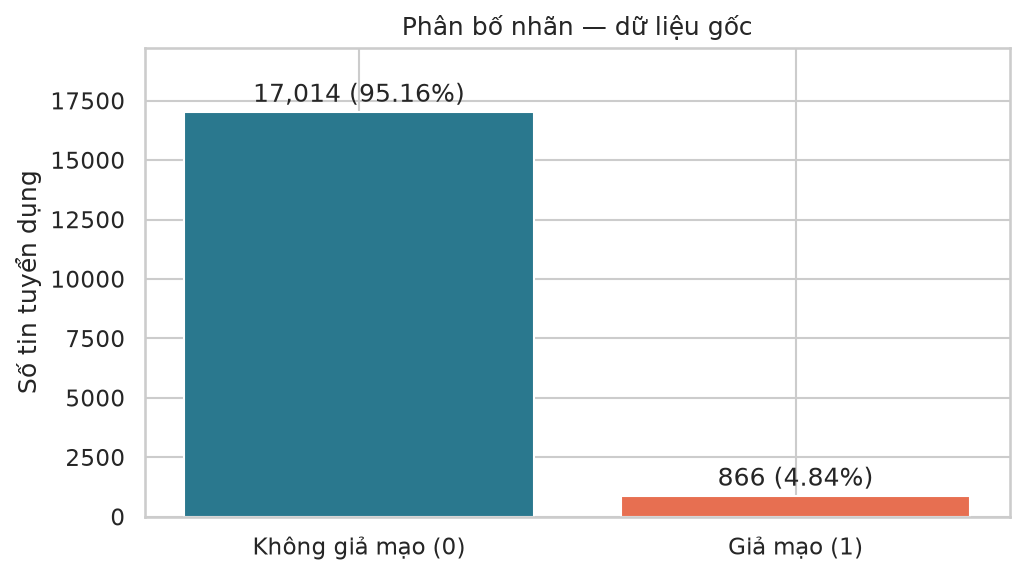

In [3]:
missing = pd.DataFrame({'missing_count': raw.isna().sum(), 'missing_pct': raw.isna().mean()*100})
display(missing.sort_values('missing_pct', ascending=False))
counts = raw.fraudulent.value_counts().sort_index()
display(pd.DataFrame({'count':counts,'pct':counts/len(raw)*100}))
display(Image(filename=str(ROOT/'midterm_artifacts/08_class_distribution_raw.png')))

## 3. Chuẩn bị dữ liệu và kiểm toán leakage
Loại bản trùng hoàn toàn theo predictor sau kiểm tra nhãn mâu thuẫn. Tách nhóm bằng nội dung chuẩn hóa của title/description/requirements. Manifest kế thừa giữa kỳ giữ nguyên test. Các hàm fit/transform nằm trong `src/fakejobs/features.py`; không fit bộ biến đổi trên toàn dữ liệu.

In [4]:
parts, groups, folds = load_data()
display(pd.DataFrame([{'split':name,'rows':len(df),'fake':int(df.fraudulent.sum()),
    'fake_pct':100*df.fraudulent.mean()} for name,df in parts.items()]))
display(pd.read_csv(ROOT/'results/fold_audit.csv'))
print('Các kiểm tra nhóm, số tin giả và hash dữ liệu đã vượt qua.')

,split,rows,fake,fake_pct
0,train,10836,530,4.891104
1,validation,3340,182,5.449102
2,test,3389,144,4.249041


,fold,fit_real,fit_fake,eval_real,eval_fake,fake_groups,group_overlap
0,1,8244,424,2062,106,84,0
1,2,8245,424,2061,106,83,0
2,3,8245,424,2061,106,81,0
3,4,8245,424,2061,106,83,0
4,5,8245,424,2061,106,81,0


Các kiểm tra nhóm, số tin giả và hash dữ liệu đã vượt qua.


,count,mean,std,min,25%,50%,75%,max
title_word_count,10836.0,3.739480,2.056595,1.000000,2.000000,3.000000,4.000000,19.000000
log1p_title_word_count,10836.0,1.480599,0.372663,0.693147,1.098612,1.386294,1.609438,2.995732
company_profile_word_count,8849.0,112.154255,80.989626,1.000000,54.000000,96.000000,148.000000,885.000000
log1p_company_profile_word_count,8849.0,4.431341,0.869573,0.693147,4.007333,4.574711,5.003946,6.786717
description_word_count,10835.0,168.728196,123.538070,1.000000,84.000000,143.000000,223.000000,1268.000000
log1p_description_word_count,10835.0,4.866676,0.786123,0.693147,4.442651,4.969813,5.411646,7.145984
requirements_word_count,9276.0,91.065114,79.928187,1.000000,38.000000,73.000000,118.000000,939.000000
log1p_requirements_word_count,9276.0,4.169656,0.912067,0.693147,3.663562,4.304065,4.779123,6.845880
benefits_word_count,6588.0,49.183971,56.233215,1.000000,10.000000,31.000000,69.000000,583.000000
log1p_benefits_word_count,6588.0,3.296180,1.215558,0.693147,2.397895,3.465736,4.248495,6.369901


,feature,observed_count,Q1,Q3,IQR,lower,upper,outlier_count,outlier_pct,note
0,title_word_count,10836,2.0,4.0,2.0,-1.0,7.0,672,6.201550,Áp dụng IQR
1,company_profile_word_count,8849,54.0,148.0,94.0,-87.0,289.0,371,4.192564,Áp dụng IQR
2,description_word_count,10835,84.0,223.0,139.0,-124.5,431.5,392,3.617905,Áp dụng IQR
3,requirements_word_count,9276,38.0,118.0,80.0,-82.0,238.0,472,5.088400,Áp dụng IQR
4,benefits_word_count,6588,10.0,69.0,59.0,-78.5,157.5,288,4.371585,Áp dụng IQR


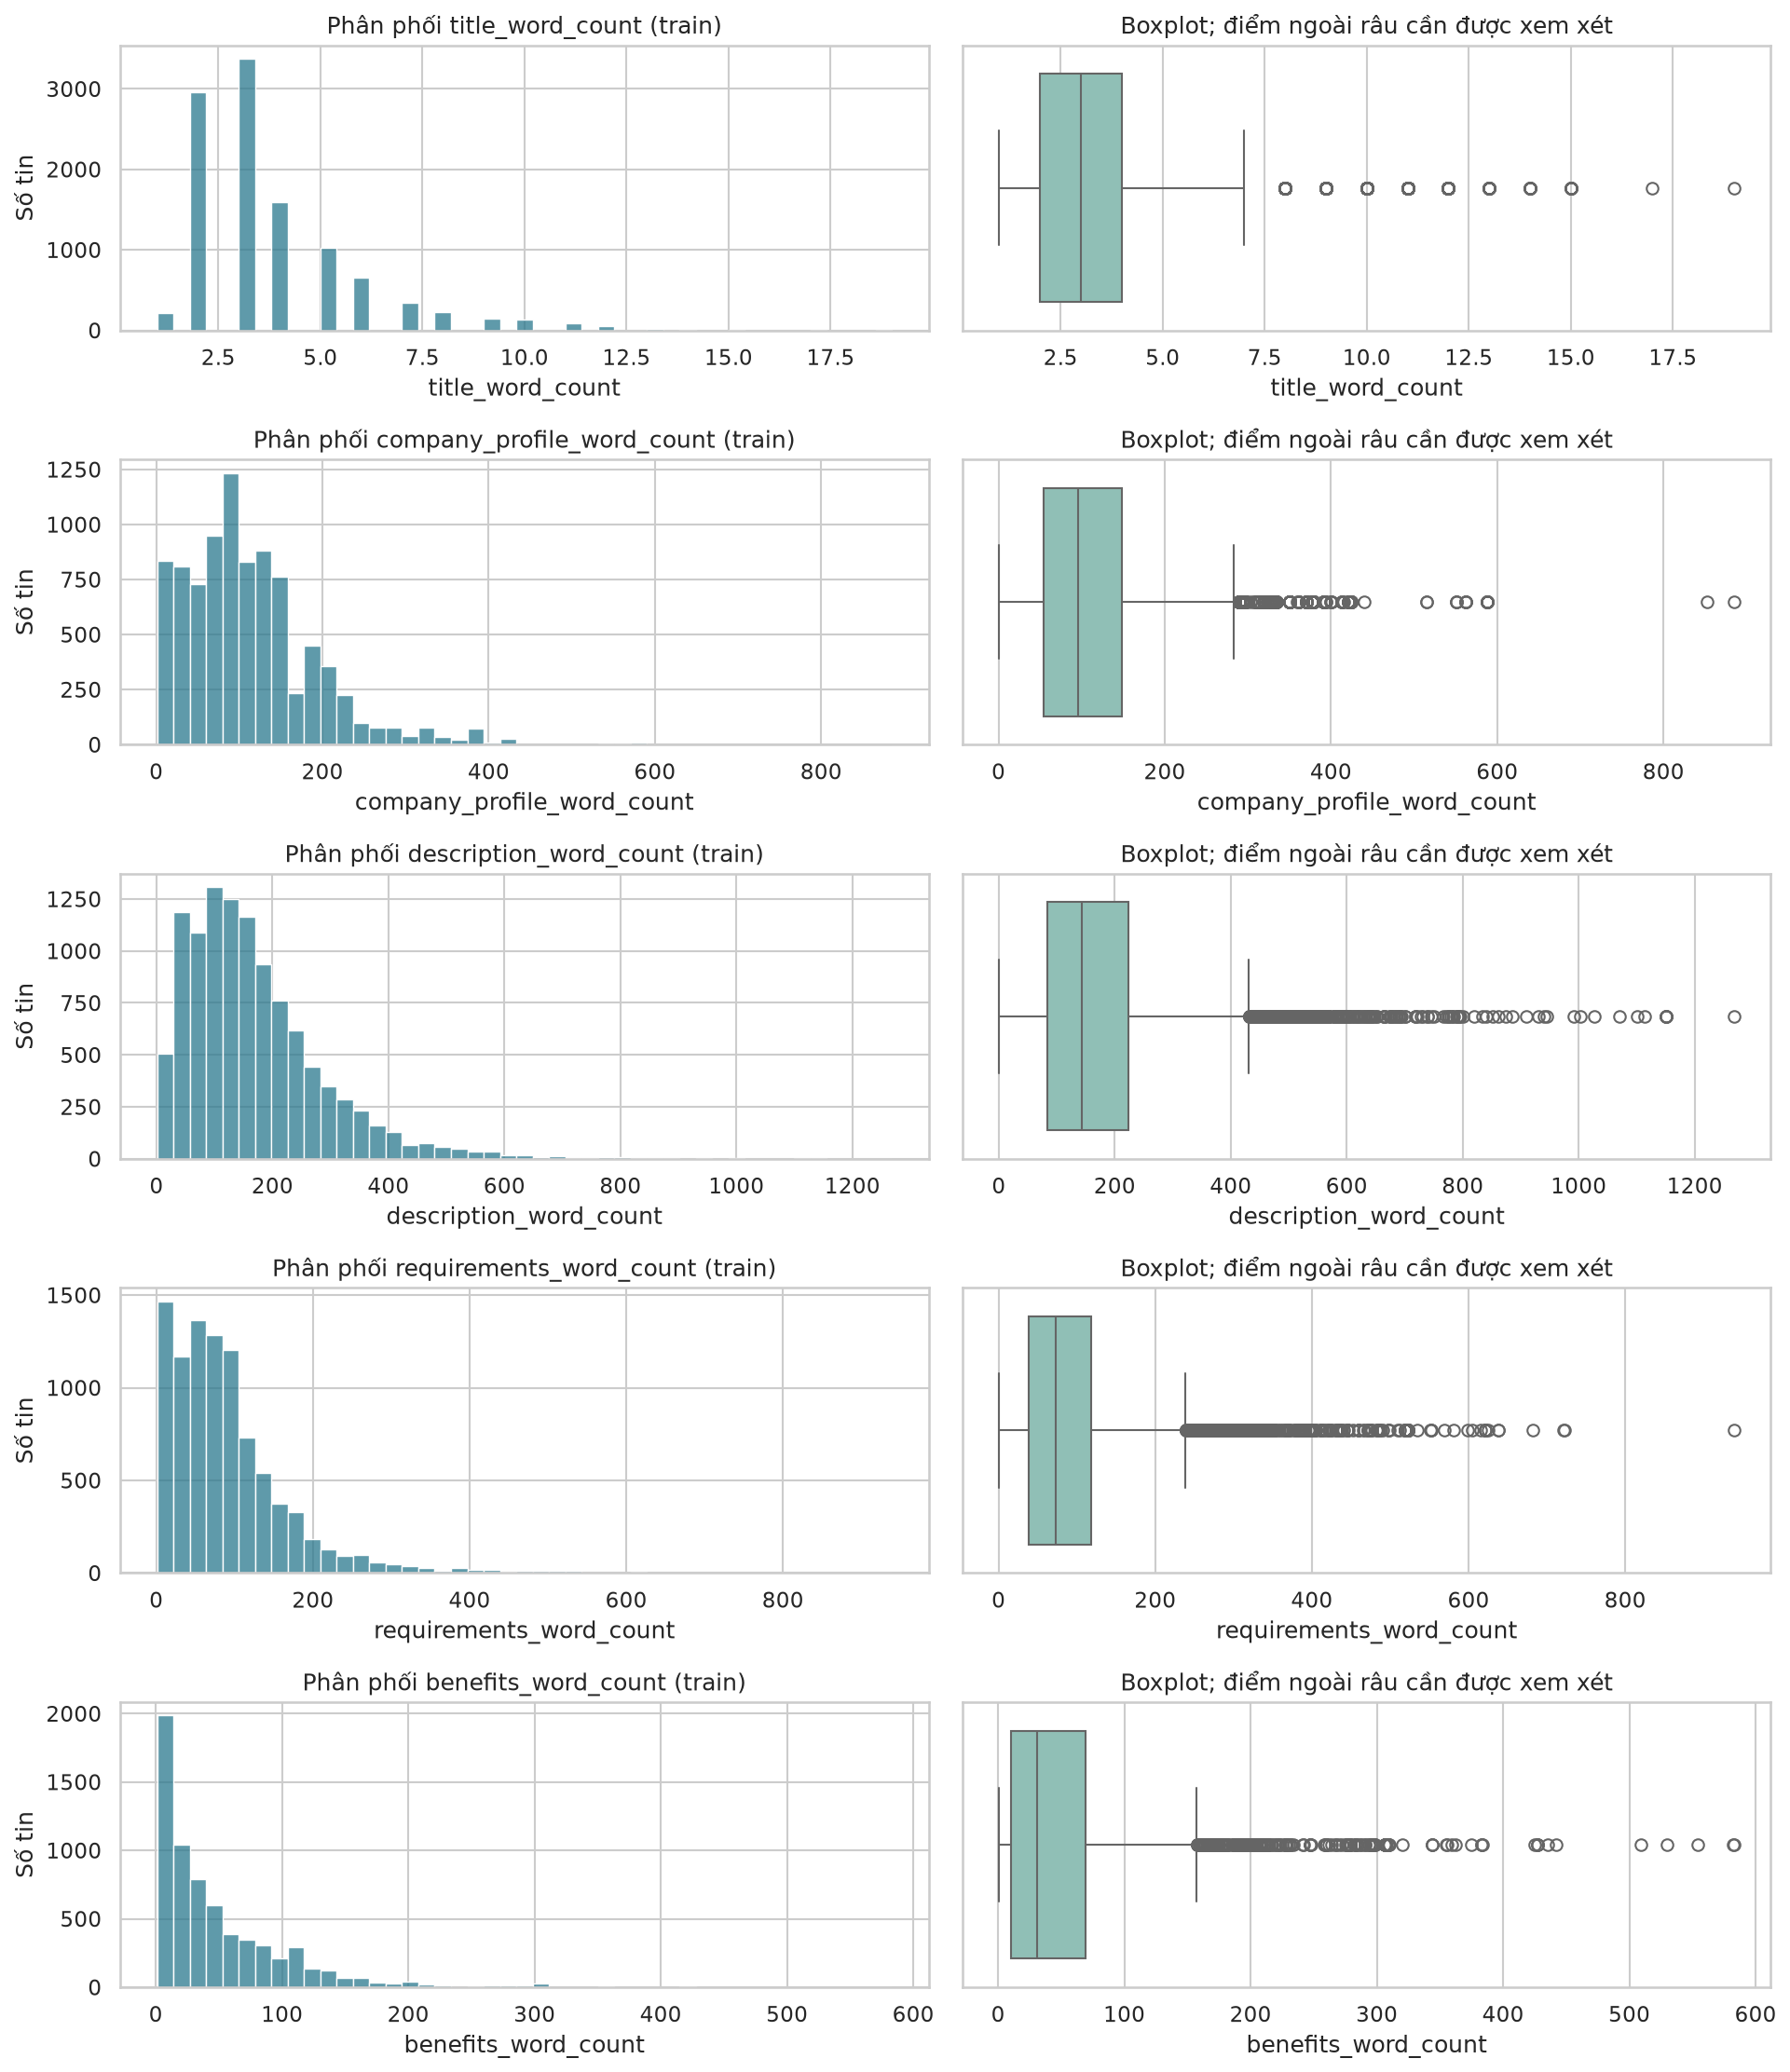

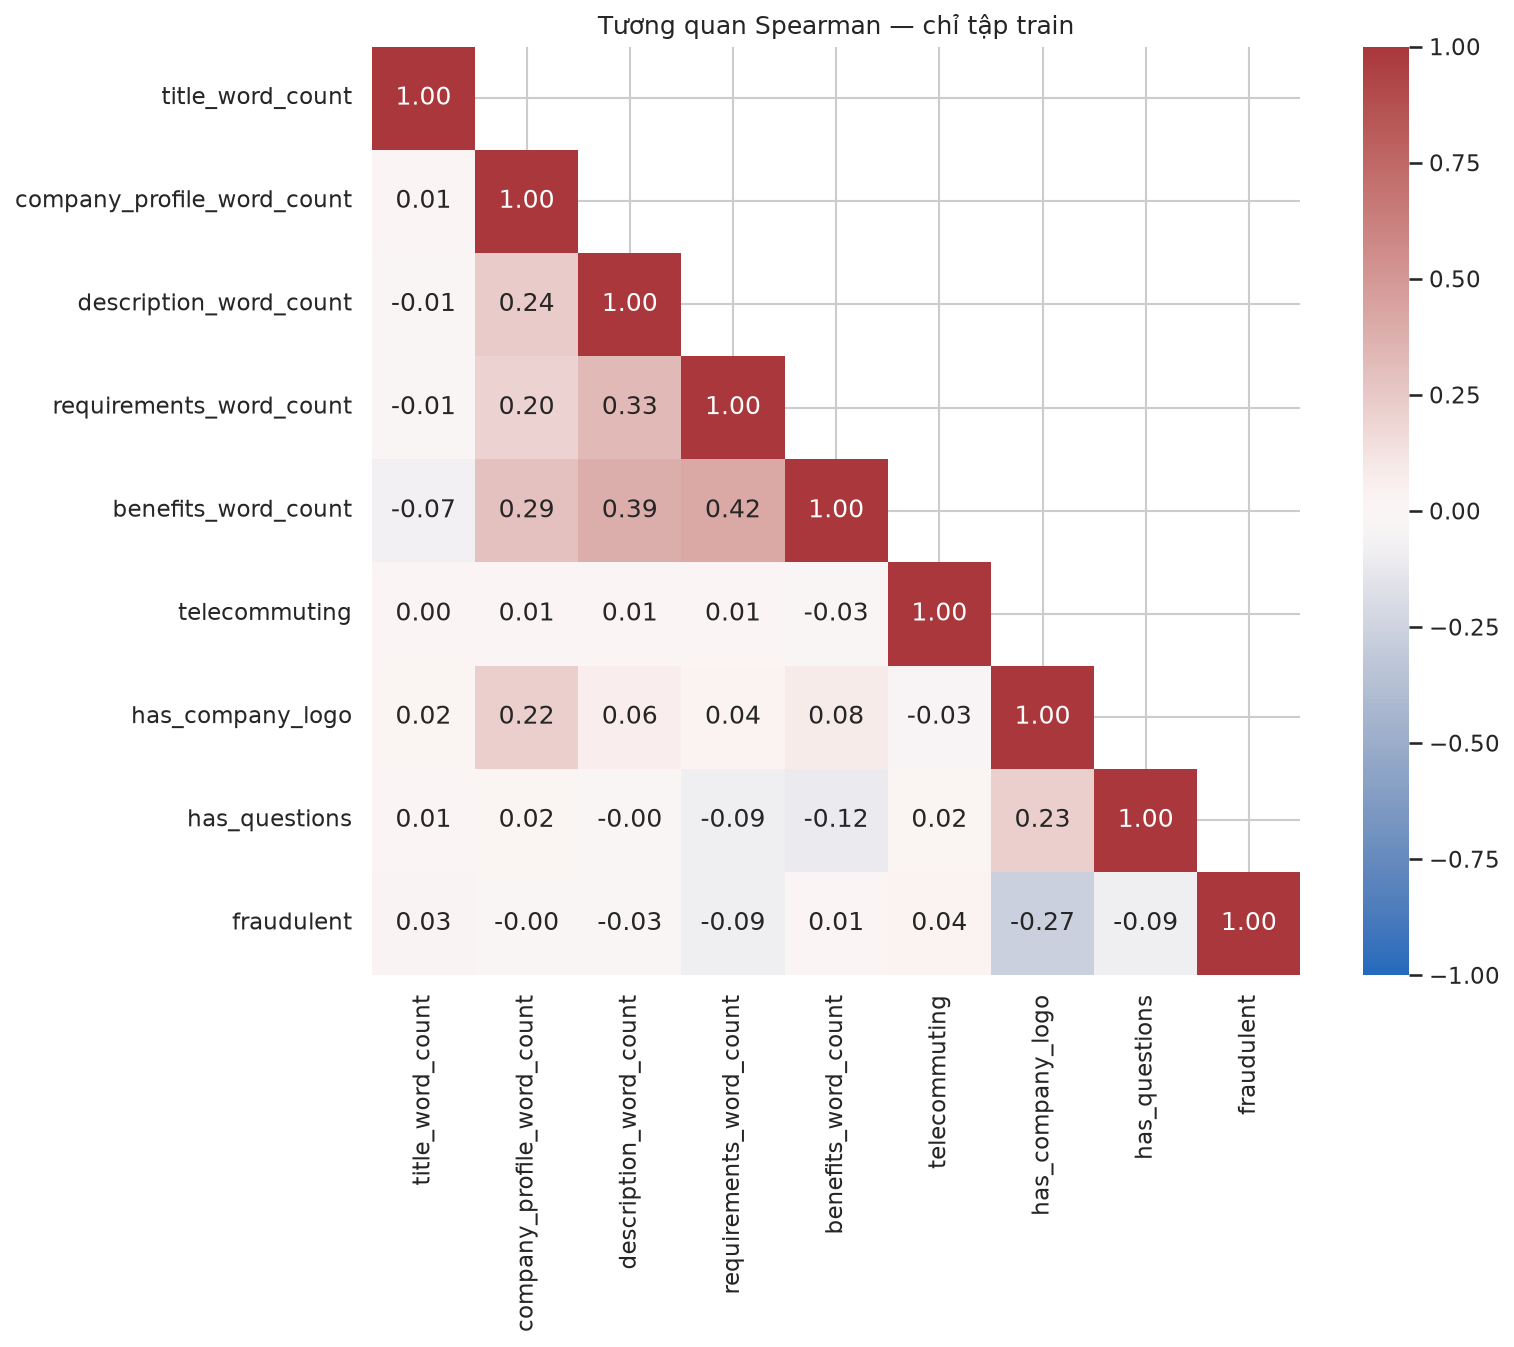

In [5]:
train_features = make_features(parts['train'])
display(train_features.filter(like='_word_count').describe().T)
display(pd.read_csv(ROOT/'midterm_artifacts/07_iqr_train.csv'))
display(Image(filename=str(ROOT/'midterm_artifacts/07_outlier_distributions_train.png')))
display(Image(filename=str(ROOT/'midterm_artifacts/09_correlation_train.png')))

Không tự xóa tin dài theo IQR; log1p giảm đuôi phân phối. Median/mode/scaler/OHE/TF-IDF được học riêng trong mỗi phần fit. 5-fold StratifiedGroupKFold có 106 tin giả và 81–84 nhóm giả ở mỗi fold đánh giá; nhóm train/eval không giao nhau. Phân tầng hỗ trợ giữ tỷ lệ nhưng không bảo đảm mọi tập dữ liệu đều cân bằng hoàn hảo.

## 4. Modeling — 3 thuật toán và baseline
8 cấu hình/họ × 3 họ × 5 fold = 120 fit, thêm 5 Dummy. CV dùng AP để chọn cấu hình. F1 trong bảng CV ở ngưỡng mặc định chỉ dùng mô tả, không phải ngưỡng vận hành cuối. Toàn bộ fit có log trong CSV; cấu hình chưa hội tụ được hiển thị minh bạch.

,config_id,model,params
0,LogisticRegression_01,LogisticRegression,"{'C': 0.1, 'class_weight': None}"
1,LogisticRegression_02,LogisticRegression,"{'C': 0.1, 'class_weight': 'balanced'}"
2,LogisticRegression_03,LogisticRegression,"{'C': 1, 'class_weight': None}"
3,LogisticRegression_04,LogisticRegression,"{'C': 1, 'class_weight': 'balanced'}"
4,LogisticRegression_05,LogisticRegression,"{'C': 10, 'class_weight': None}"
5,LogisticRegression_06,LogisticRegression,"{'C': 10, 'class_weight': 'balanced'}"
6,LogisticRegression_07,LogisticRegression,"{'C': 100, 'class_weight': None}"
7,LogisticRegression_08,LogisticRegression,"{'C': 100, 'class_weight': 'balanced'}"
8,LinearSVM_01,LinearSVM,"{'C': 0.1, 'class_weight': None}"
9,LinearSVM_02,LinearSVM,"{'C': 0.1, 'class_weight': 'balanced'}"


,config_id,model,params,AP_mean,AP_std,ROC_AUC_mean,F1_default_mean,recall_default_mean,precision_default_mean,fit_seconds_mean,n_folds
0,LinearSVM_03,LinearSVM,"{""C"": 1, ""class_weight"": null}",0.830869,0.075049,0.970865,0.747116,0.639623,0.910894,0.555539,5
1,LogisticRegression_08,LogisticRegression,"{""C"": 100, ""class_weight"": ""balanced""}",0.827923,0.073943,0.972836,0.745823,0.745283,0.757355,1.634073,5
2,RandomForest_03,RandomForest,"{""class_weight"": null, ""max_depth"": null, ""min_samples_leaf"": 1}",0.814701,0.071416,0.973925,0.578193,0.411321,0.987585,15.014620,5
3,Dummy_01,Dummy,{},0.048911,0.000010,0.500000,0.000000,0.000000,0.000000,0.000925,5


,config_id,fold,warnings
13,LinearSVM_06,1,"Liblinear failed to converge, increase the number of iterations."
14,LinearSVM_07,1,"Liblinear failed to converge, increase the number of iterations."
15,LinearSVM_08,1,"Liblinear failed to converge, increase the number of iterations."
38,LinearSVM_06,2,"Liblinear failed to converge, increase the number of iterations."
39,LinearSVM_07,2,"Liblinear failed to converge, increase the number of iterations."
40,LinearSVM_08,2,"Liblinear failed to converge, increase the number of iterations."
63,LinearSVM_06,3,"Liblinear failed to converge, increase the number of iterations."
64,LinearSVM_07,3,"Liblinear failed to converge, increase the number of iterations."
65,LinearSVM_08,3,"Liblinear failed to converge, increase the number of iterations."
89,LinearSVM_07,4,"Liblinear failed to converge, increase the number of iterations."


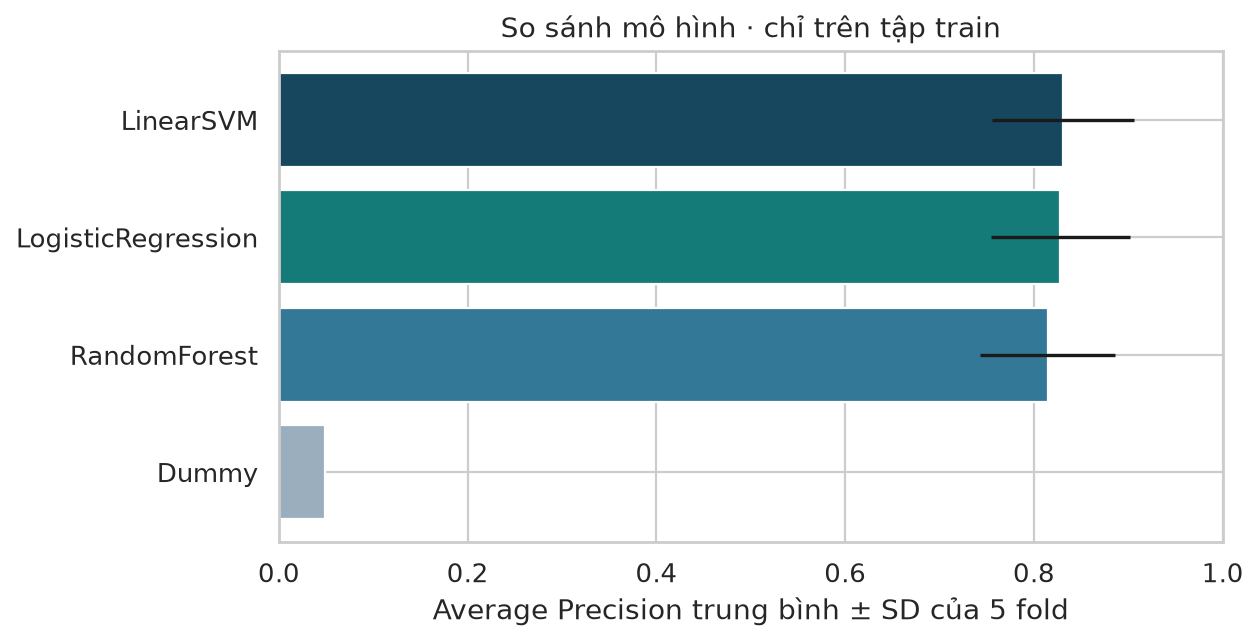

{'config_id': 'LinearSVM_03',
 'model': 'LinearSVM',
 'params': {'C': 1, 'class_weight': None},
 'AP_mean': 0.830868695092873,
 'AP_std': 0.07504893520385902,
 'selected_using': 'train CV only'}

In [6]:
protocol = load_json(ROOT/'results/protocol.json')
display(pd.DataFrame(protocol['configurations']))
cv = pd.read_csv(ROOT/'results/cv_results.csv')
assert len(cv)==125
display(pd.read_csv(ROOT/'results/best_per_model.csv'))
display(cv.loc[cv.warnings.notna(), ['config_id','fold','warnings']])
display(Image(filename=str(ROOT/'results/figures/01_cv_ap.png')))
display(load_json(ROOT/'results/selection.json'))

### Ablation
LR với C và class_weight đã chọn, giữ cùng 5 fold. `metadata_only` gồm cả độ dài văn bản nhưng không TF-IDF. Các ablation là phân tích tác động trên train; không dùng để đổi mô hình sau khi xem test.

,variant,AP_mean,AP_std,F1_default_mean,recall_default_mean
0,combined,0.827923,0.073943,0.745823,0.745283
1,metadata_only,0.505688,0.078422,0.442482,0.767925
2,no_log,0.827516,0.073859,0.742020,0.737736
3,no_logo,0.824960,0.079051,0.749389,0.739623
4,text_only,0.819921,0.075728,0.765265,0.690566


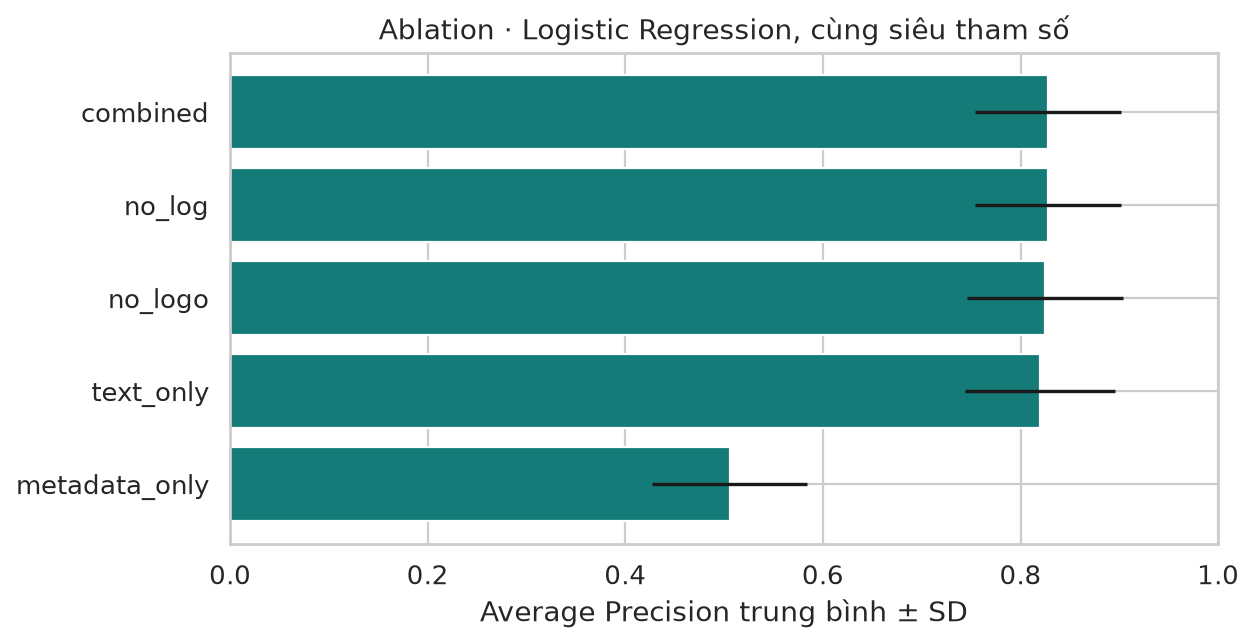

In [7]:
display(pd.read_csv(ROOT/'results/ablation_summary.csv'))
display(Image(filename=str(ROOT/'results/figures/02_ablation.png')))

## 5. Evaluation — ngưỡng và test đã khóa
Chọn ngưỡng chỉ trên validation, sau đó khóa checksum mô hình/protocol. Điểm SVM là decision score, không phải xác suất. AP không nội suy của scikit-learn khác diện tích PR tính hình thang.

{'threshold': -0.37317585243277074,
 'precision_target': 0.8,
 'target_feasible_on_validation': True,
 'fit_seconds': 18.33116489998065,
 'batch_predict_seconds': 4.240699200017843,
 'AP': 0.9035526972463648,
 'ROC_AUC': 0.9873146169852945,
 'precision': 0.8288770053475936,
 'recall': 0.8516483516483516,
 'F1': 0.8401084010840109,
 'accuracy': 0.9823353293413174,
 'alert_rate': 0.05598802395209581,
 'TN': 3126,
 'FP': 32,
 'FN': 27,
 'TP': 155}

{'selection': {'config_id': 'LinearSVM_03',
  'model': 'LinearSVM',
  'params': {'C': 1, 'class_weight': None},
  'AP_mean': 0.830868695092873,
  'AP_std': 0.07504893520385902,
  'selected_using': 'train CV only'},
 'threshold': -0.37317585243277074,
 'score_type': 'decision_score',
 'validation_precision_goal_met': True,
 'model_sha256': '3592e1ffa4766ddd7755c88b6d1e42f51abb26d216ebccfa03035b30e156093b',
 'protocol_sha256': 'b3984cfa66afb697f4c4e2a745b172daadd6a1030db52c415d9bb18a555194ab',
 'locked_before_test': True,
 'test_used_for_selection': False,
 'n_features': 15231}

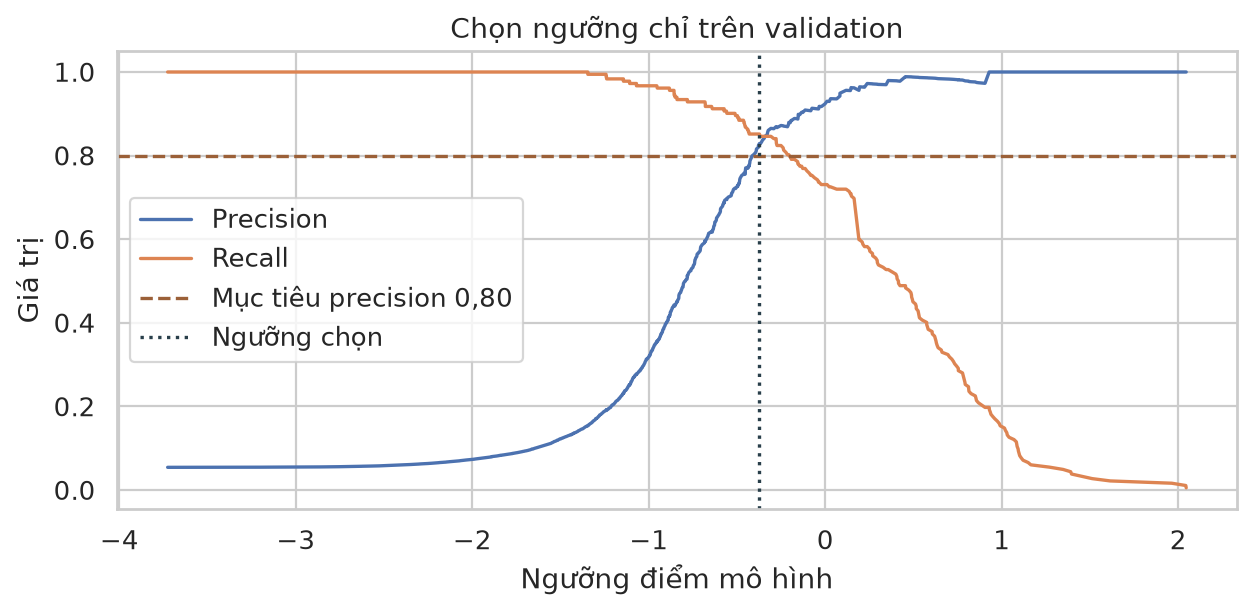

In [8]:
display(load_json(ROOT/'results/validation_metrics.json'))
lock = load_json(ROOT/'models/lock.json')
assert sha(ROOT/'models/fake_job_detector.joblib')==lock['model_sha256']
assert sha(ROOT/'results/protocol.json')==lock['protocol_sha256']
display(lock)
display(Image(filename=str(ROOT/'results/figures/05_validation_threshold.png')))

,selected_model
model,LinearSVM
threshold,-0.373176
n_samples,3389
n_fake,144
batch_predict_seconds,4.216215
milliseconds_per_post_batch,1.244088
AP,0.878146
ROC_AUC,0.986792
precision,0.745342
recall,0.833333


,dummy_prior
AP,0.04249
ROC_AUC,0.50000
precision,0.00000
recall,0.00000
F1,0.00000
accuracy,0.95751
alert_rate,0.00000
TN,3245.00000
FP,0.00000
FN,144.00000


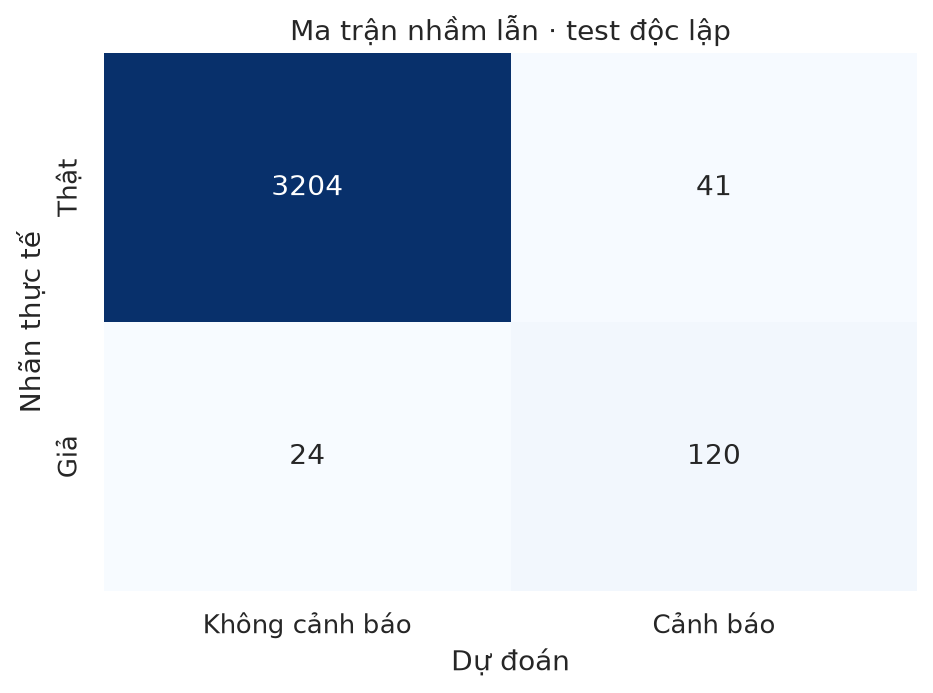

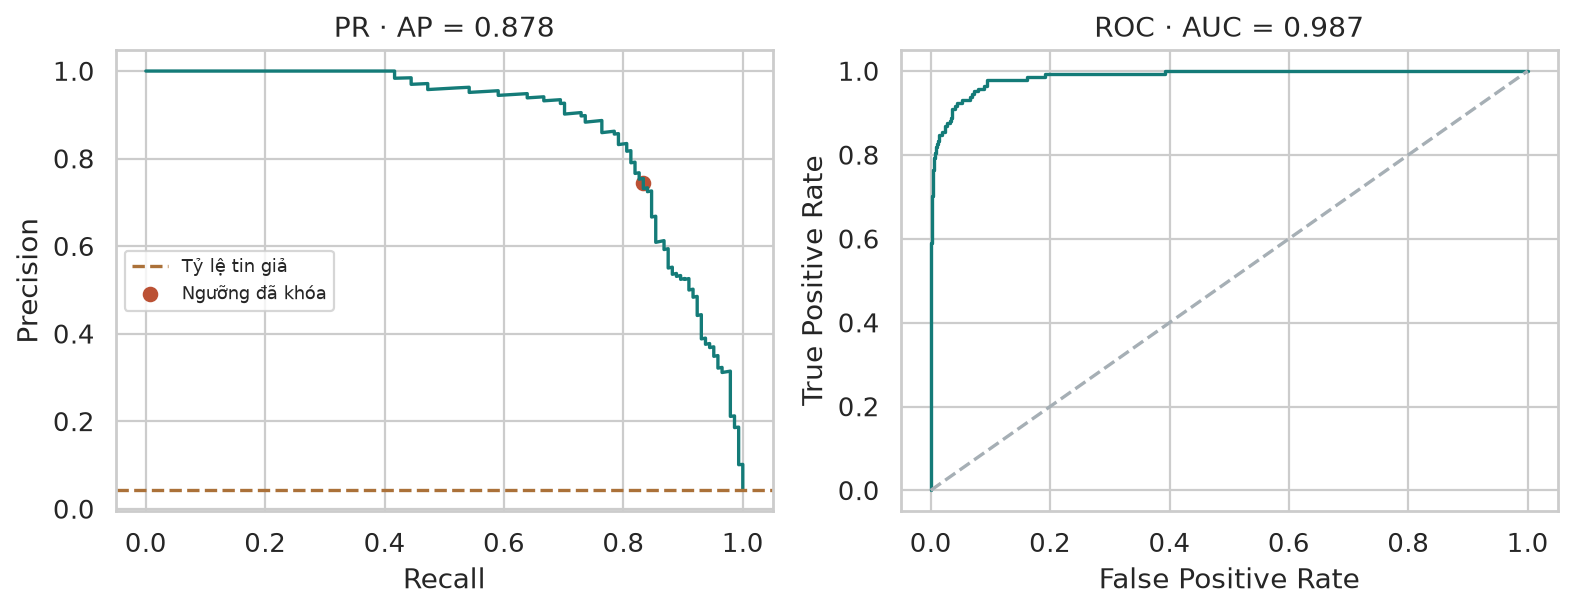

In [9]:
test = load_json(ROOT/'results/test_metrics.json')
pred = pd.read_csv(ROOT/'results/test_predictions.csv')
recomputed = metrics(pred.fraudulent, pred.score, test['threshold'])
for key,value in recomputed.items():
    assert np.isclose(value,test[key]), key
display(pd.Series(test).drop('dummy_prior').to_frame('selected_model'))
display(pd.Series(test['dummy_prior']).to_frame('dummy_prior'))
display(Image(filename=str(ROOT/'results/figures/04_confusion.png')))
display(Image(filename=str(ROOT/'results/figures/03_test_curves.png')))

,low,high
AP,0.816549,0.924191
ROC_AUC,0.978824,0.992975
precision,0.658517,0.818182
recall,0.757807,0.894140
F1,0.716043,0.843313
alert_rate,0.038018,0.059208


Bootstrap theo nhóm: 1000 lần; nhóm: 3071


,field,value,n,fake,TP,FP,FN,recall,precision
0,has_company_logo,0.0,759,99,80,31,19,0.808081,0.720721
1,has_company_logo,1.0,2630,45,40,10,5,0.888889,0.800000
2,has_questions,0.0,1789,110,93,28,17,0.845455,0.768595
3,has_questions,1.0,1600,34,27,13,7,0.794118,0.675000
4,telecommuting,0.0,3242,136,114,33,22,0.838235,0.775510
5,telecommuting,1.0,147,8,6,8,2,0.750000,0.428571


,job_id,error_type,actual,predicted,score,title,has_company_logo,description_excerpt
0,4812,FN,1,0,-1.439565,Sir Awesome,0,"Lorem ipsum dolor sit amet, consectetur adipiscing elit. Etia..."
1,5363,FN,1,0,-1.155059,Licensed Life Insurance Agent,1,"We need someone who is smart, funny, great with people, wants..."
2,17654,FN,1,0,-1.085593,Senior JavaScript Developer,1,RideAmigos is hiring a senior level JavaScript developer to w...
3,1768,FP,0,1,0.449306,Accounting/Data entry,0,Responsibilities :• Responsible for the delivery of outstandi...
4,1092,FP,0,1,0.396858,Book Keeper,0,Description The bookkeeper will process the company’s financi...
5,3471,FP,0,1,0.289479,Controls - PLC Programmer,0,"CONTROLS – PLC PROGRAMMEREDMONTON, ALBERTAPackers Plus is the..."


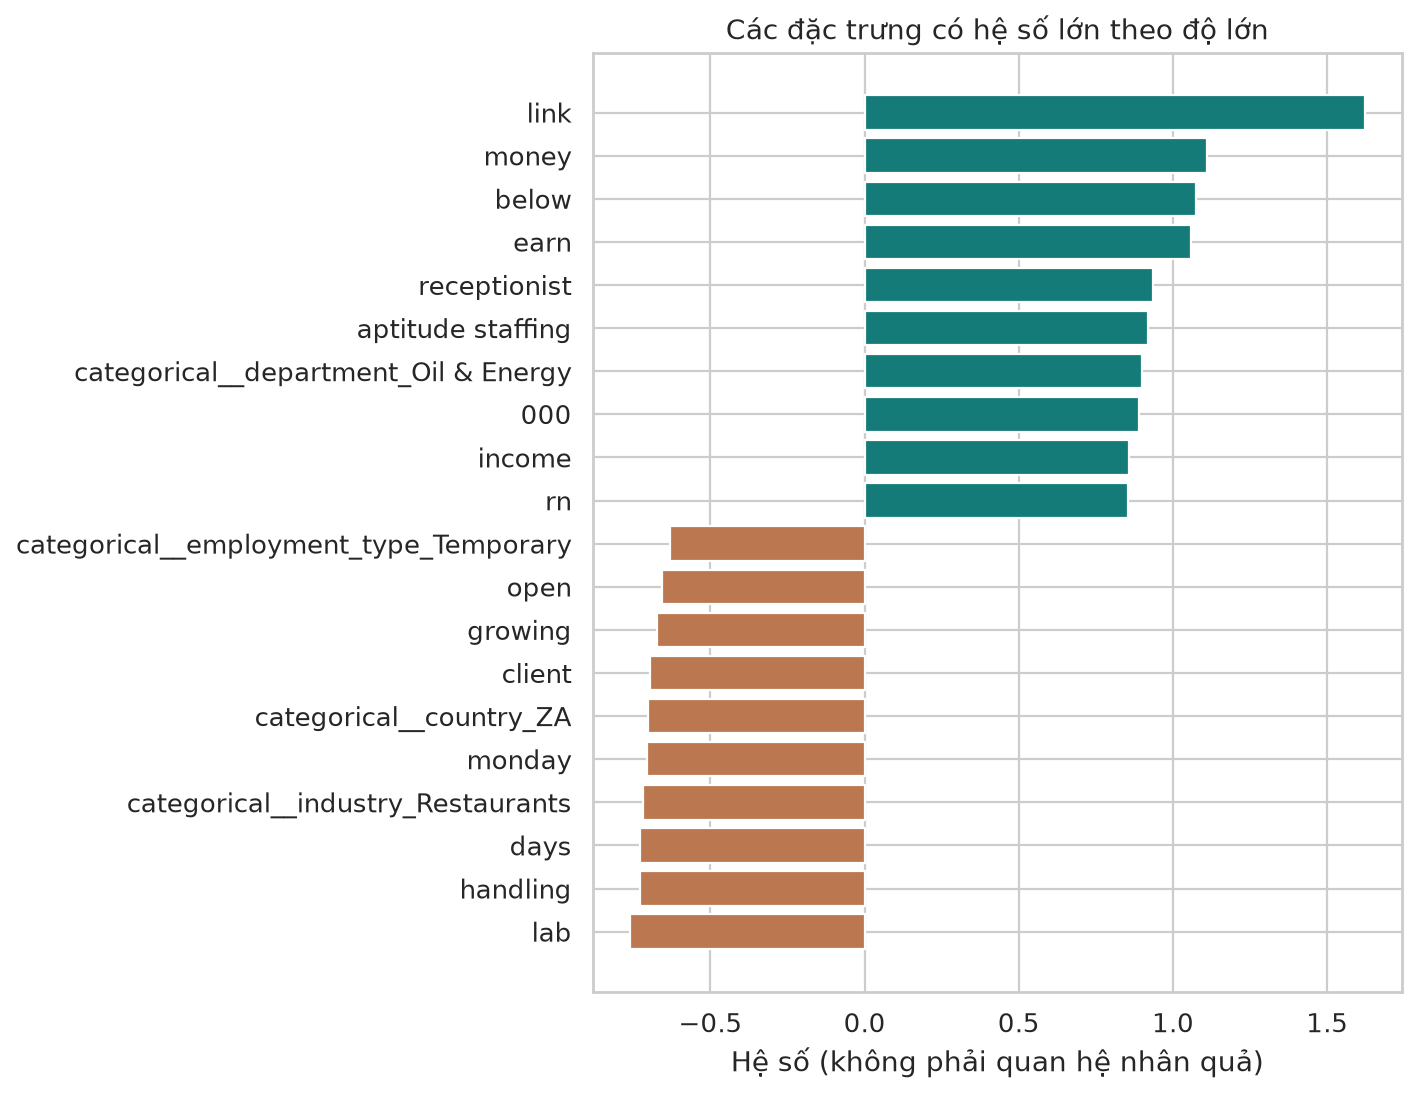

In [10]:
bootstrap = load_json(ROOT/'results/test_bootstrap.json')
display(pd.DataFrame(bootstrap['intervals']).T)
print('Bootstrap theo nhóm:', bootstrap['replicates'], 'lần; nhóm:', bootstrap['groups'])
display(pd.read_csv(ROOT/'results/error_slices.csv'))
display(pd.DataFrame(load_json(ROOT/'results/error_cases.json')))
display(Image(filename=str(ROOT/'results/figures/06_feature_weights.png')))

Khoảng tin cậy có điều kiện trên mô hình đã fit, không bao gồm toàn bộ biến động huấn luyện hoặc dịch chuyển miền. Phân tích lỗi test là hậu kiểm, không dùng để chỉnh ngưỡng/thuật toán. Tin gần trùng hoặc cùng doanh nghiệp chưa được cô lập hoàn toàn; cần test ngoài nguồn trước pilot.

### 5.7 Chẩn đoán theo company_profile
Đây là phân tích hậu kiểm ở ngưỡng đã khóa. Profile trùng không phải company ID. Nhóm không có/chưa thấy profile có 841 tin, trong đó 654 tin thiếu profile; không gọi toàn bộ nhóm này là doanh nghiệp mới. Precision 72,22%, recall 79,82% trên lát cắt này cần được đọc cùng kết quả gộp.

In [11]:
display(pd.read_csv(ROOT/'results/company_profile_slices.csv'))
display(load_json(ROOT/'results/company_profile_slices.json'))

,split,slice,n,fake,fake_rate,TP,FP,FN,recall,recall_wilson_low,recall_wilson_high,recall_boot_low,recall_boot_high,precision,precision_boot_low,precision_boot_high,lookup_TP,lookup_FP,lookup_FN
0,test,tat_ca,3389,144,0.042490,120,41,24,0.833333,0.763976,0.885368,0.757807,0.894140,0.745342,0.658517,0.818182,30,0,114
1,test,profile_da_thay_trong_train,2548,30,0.011774,29,6,1,0.966667,0.833292,0.994092,0.875000,1.000000,0.828571,0.689655,0.935582,30,0,0
2,test,khong_co_hoac_chua_thay,841,114,0.135553,91,35,23,0.798246,0.715415,0.861630,0.699180,0.877328,0.722222,0.618231,0.813433,0,0,114
3,test,khong_co_profile,654,103,0.157492,82,30,21,0.796117,0.708336,0.862603,0.691324,0.877053,0.732143,0.614007,0.826132,0,0,103
4,test,profile_chua_thay,187,11,0.058824,9,5,2,0.818182,0.523014,0.948633,0.243750,1.000000,0.642857,0.111111,0.905797,0,0,11
5,validation,tat_ca,3340,182,0.054491,155,32,27,0.851648,0.792760,0.895998,0.783780,0.906082,0.828877,0.767152,0.890177,60,0,122
6,validation,profile_da_thay_trong_train,2542,60,0.023603,51,3,9,0.850000,0.738852,0.919027,0.727273,0.945455,0.944444,0.874899,1.000000,60,0,0
7,validation,khong_co_hoac_chua_thay,798,122,0.152882,104,29,18,0.852459,0.778809,0.904590,0.773575,0.916084,0.781955,0.693659,0.867580,0,0,122
8,validation,khong_co_profile,636,117,0.183962,101,29,16,0.863248,0.789360,0.914040,0.784479,0.925542,0.776923,0.684161,0.865508,0,0,117
9,validation,profile_chua_thay,162,5,0.030864,3,0,2,0.600000,0.230720,0.882382,0.083333,1.000000,1.000000,1.000000,1.000000,0,0,5


[{'split': 'test',
  'slice': 'tat_ca',
  'n': 3389,
  'fake': 144,
  'fake_rate': 0.0425,
  'TP': 120,
  'FP': 41,
  'FN': 24,
  'recall': 0.8333,
  'recall_wilson_low': 0.764,
  'recall_wilson_high': 0.8854,
  'recall_boot_low': 0.7578,
  'recall_boot_high': 0.8941,
  'precision': 0.7453,
  'precision_boot_low': 0.6585,
  'precision_boot_high': 0.8182,
  'lookup_TP': 30,
  'lookup_FP': 0,
  'lookup_FN': 114},
 {'split': 'test',
  'slice': 'profile_da_thay_trong_train',
  'n': 2548,
  'fake': 30,
  'fake_rate': 0.0118,
  'TP': 29,
  'FP': 6,
  'FN': 1,
  'recall': 0.9667,
  'recall_wilson_low': 0.8333,
  'recall_wilson_high': 0.9941,
  'recall_boot_low': 0.875,
  'recall_boot_high': 1.0,
  'precision': 0.8286,
  'precision_boot_low': 0.6897,
  'precision_boot_high': 0.9356,
  'lookup_TP': 30,
  'lookup_FP': 0,
  'lookup_FN': 0},
 {'split': 'test',
  'slice': 'khong_co_hoac_chua_thay',
  'n': 841,
  'fake': 114,
  'fake_rate': 0.1356,
  'TP': 91,
  'FP': 35,
  'FN': 23,
  'recall': 0.7

### 5.8 So sánh pipeline bổ sung và giới hạn kiểm định
NB dùng TF-IDF text-only; HistGradientBoosting dùng combined + SelectKBest 2.000 đặc trưng. Khác biểu diễn nên không cô lập tác động thuật toán.

Năm fold dùng tập fit chồng lấn và cũng được dùng chọn cấu hình. Nadeau–Bengio/Holm không loại bỏ selection bias; Friedman trên fold không thay thế thiết kế nhiều dataset độc lập. P-value chỉ để truy nguyên phân tích thăm dò, không xác nhận ưu thế/tương đương. Validation đã dùng chọn ngưỡng, bootstrap validation cũng chỉ là chẩn đoán.

Bảng thời gian dưới lấy trực tiếp JSON lịch sử: fit + chấm validation + AP, không gồm preprocessing. Mã mới tách fit/predict cho lượt chạy mới; không đổi hồi tố số đo. RF n_jobs=2, các native pool giới hạn 1.

In [12]:
comparison = load_json(ROOT/'results/extension/validation_compare.json')
timing = pd.DataFrame(comparison['models']).T.rename(columns={'fit_seconds':'fit_plus_validation_seconds_historical'})
display(timing)
display(pd.read_csv(ROOT/'results/extension/stats_cv_pairwise.csv'))
display(comparison['consistency_check'])
display(load_json(ROOT/'results/extension/measurement_provenance.json'))

,config_id,AP_validation,fit_plus_validation_seconds_historical
HistGradientBoosting,HistGradientBoosting_04,0.917971,66.59216
LinearSVM,LinearSVM_03,0.90377,0.906162
LogisticRegression,LogisticRegression_08,0.899201,4.606751
RandomForest,RandomForest_03,0.895343,42.647823
NaiveBayes,NaiveBayes_01,0.835266,0.029806


,comparison,config_other,AP_svm_mean,AP_other_mean,mean_diff,sd_diff,folds_svm_better,t_plain,p_plain,t_nadeau_bengio,p_nadeau_bengio,p_wilcoxon_exact,p_nadeau_bengio_holm
0,LinearSVM vs HistGradientBoosting,HistGradientBoosting_04,0.830869,0.848803,-0.017934,0.027507,1,-1.457902,0.218611,-0.971934,0.386120,0.1875,1.000000
1,LinearSVM vs LogisticRegression,LogisticRegression_08,0.830869,0.827923,0.002946,0.008398,3,0.784363,0.476674,0.522909,0.628665,1.0000,1.000000
2,LinearSVM vs RandomForest,RandomForest_03,0.830869,0.814701,0.016168,0.022116,4,1.634693,0.177453,1.089796,0.337058,0.1875,1.000000
3,LinearSVM vs NaiveBayes,NaiveBayes_01,0.830869,0.745801,0.085068,0.039393,5,4.828717,0.008469,3.219144,0.032307,0.0625,0.129227


{'locked_validation_AP': 0.9035526972463648,
 'refit_validation_AP': 0.9037701547306111,
 'abs_diff': 0.0002174574842462862,
 'environment_scikit_learn': '1.7.2'}

{'record_type': 'retrospective provenance audit, 2026-10-14; original measurements unchanged',
 'source_archive': 'Nhom7_TrackB_Final_2026-10-13.zip',
 'source_validation_compare_sha256': '49416bafbb0350512e92a7401f1d83c18cb568765d343917963bc4f0718dd293',
 'original_extension_code_sha256': '9cc448fd02410202455c2fc663df147aa21284620c4a5ccb893c0e74ffb3cadb',
 'historical_environment': {'python': '3.12.3',
  'scikit-learn': '1.7.2',
  'os': 'Linux, stated in unit-test log',
  'hardware': 'not recorded',
  'other_library_versions': 'not recorded for this run'},
 'main_environment_file': 'results/environment.json (separate Windows run; not extension environment)',
 'historical_timing_scope': 'timer begins before classifier.fit and ends after validation scoring and AP calculation; feature_views excluded',
 'parallelism': 'threadpool_limits(1) for native pools; RandomForest estimator n_jobs=2',
 'future_timing_scope': 'extension.py v2 separates fit_seconds and predict_seconds; not retroactive

### 5.10 Phân tích bổ sung ngày 18/10
Nested CV trên train: 3 outer × 3 inner, tám cấu hình mỗi họ LR/SVM, cùng biểu diễn; inner chọn, outer đánh giá. Không bao phủ RF/NB/GB và không chia theo doanh nghiệp. Ablation SVM giữ C=1, class_weight=None. Calibration sigmoid học từ OOF train, chấm validation đã dùng trước đây nên chỉ là chẩn đoán. Chi phí là giả định chuẩn hóa, không phải chi phí doanh nghiệp. Không đổi bundle/ngưỡng hoặc lựa chọn theo test.

In [13]:
display(pd.read_csv(ROOT/'results/robustness/nested_summary.csv'))
display(pd.read_csv(ROOT/'results/robustness/nested_outer.csv'))
display(pd.read_csv(ROOT/'results/robustness/nested_fold_audit.csv'))
display(pd.read_csv(ROOT/'results/robustness/svm_ablation_summary.csv'))
display(pd.read_csv(ROOT/'results/robustness/calibration_validation.csv'))
display(pd.read_csv(ROOT/'results/robustness/calibration_bins.csv'))
display(pd.read_csv(ROOT/'results/robustness/cost_sensitivity.csv'))
display(pd.DataFrame(load_json(ROOT/'results/robustness/benchmark.json')['rows']))
display(load_json(ROOT/'results/robustness/protocol.json'))

,model,AP_mean,AP_std,inner_AP_mean
0,LinearSVM,0.839053,0.018649,0.779650
1,LogisticRegression,0.834348,0.024565,0.766436


,outer,config_id,model,params,inner_AP_mean,outer_AP,eval_n,eval_fake,preprocess_seconds,fit_seconds,predict_seconds,warnings
0,1,LinearSVM_05,LinearSVM,"{'C': 10, 'class_weight': None}",0.739367,0.817776,3917,218,16.268628,1.835171,0.003414,NaN
1,1,LogisticRegression_08,LogisticRegression,"{'C': 100, 'class_weight': 'balanced'}",0.723557,0.806637,3917,218,16.268628,1.800772,0.004851,NaN
2,2,LinearSVM_06,LinearSVM,"{'C': 10, 'class_weight': 'balanced'}",0.796093,0.852562,3511,159,15.449411,8.783932,0.003909,"Liblinear failed to converge, increase the number of iterations."
3,2,LogisticRegression_08,LogisticRegression,"{'C': 100, 'class_weight': 'balanced'}",0.782581,0.853449,3511,159,15.449411,1.698076,0.002713,NaN
4,3,LinearSVM_03,LinearSVM,"{'C': 1, 'class_weight': None}",0.803492,0.846822,3408,153,10.833888,0.410000,0.002185,NaN
5,3,LogisticRegression_08,LogisticRegression,"{'C': 100, 'class_weight': 'balanced'}",0.793171,0.842957,3408,153,10.833888,1.209216,0.002841,NaN


,split,fit_n,eval_n,fit_fake,eval_fake,group_overlap
0,outer_1,6919,3917,312,218,0
1,outer_1_inner_1,4645,2274,205,107,0
2,outer_1_inner_2,4651,2268,220,92,0
3,outer_1_inner_3,4542,2377,199,113,0
4,outer_2,7325,3511,371,159,0
5,outer_2_inner_1,5077,2248,236,135,0
6,outer_2_inner_2,4604,2721,278,93,0
7,outer_2_inner_3,4969,2356,228,143,0
8,outer_3,7428,3408,377,153,0
9,outer_3_inner_1,5167,2261,253,124,0


,variant,mean,std
0,combined,0.830869,0.075049
1,metadata_only,0.577640,0.057590
2,no_log,0.831158,0.074612
3,no_logo,0.828606,0.080415
4,text_only,0.818725,0.078036


,method,Brier,log_loss,AP
0,prior_train,0.051553,0.211855,0.054491
1,sigmoid_score_heuristic,0.045901,0.218877,0.903553
2,oof_logistic_sigmoid,0.013427,0.052140,0.903553


,method,bin,n,mean_probability,observed_fake_rate
0,prior_train,0,3340,0.048911,0.054491
1,sigmoid_score_heuristic,0,554,0.076863,0.000000
2,sigmoid_score_heuristic,1,1531,0.148718,0.000000
3,sigmoid_score_heuristic,2,872,0.240275,0.012615
4,sigmoid_score_heuristic,3,190,0.338636,0.084211
5,sigmoid_score_heuristic,4,50,0.444364,0.440000
6,sigmoid_score_heuristic,5,48,0.547678,0.833333
7,sigmoid_score_heuristic,6,53,0.648100,0.981132
8,sigmoid_score_heuristic,7,34,0.735161,0.970588
9,sigmoid_score_heuristic,8,8,0.839219,1.000000


,FN_over_FP_cost,locked_model_cost,all_real_cost,all_flagged_cost,alerts,review_minutes_at_2min_each
0,1,65,144,3245,161,322
1,5,161,720,3245,161,322
2,10,281,1440,3245,161,322
3,20,521,2880,3245,161,322
4,50,1241,7200,3245,161,322


,model,config_id,fit_seconds,predict_seconds,AP_validation,features
0,HistGradientBoosting,HistGradientBoosting_04,66.017660,0.840593,0.917457,2000
1,LinearSVM,LinearSVM_03,0.736948,0.003004,0.903553,15231
2,LogisticRegression,LogisticRegression_08,1.951574,0.003198,0.899132,15231
3,RandomForest,RandomForest_03,15.572058,0.295643,0.900448,15231
4,NaiveBayes,NaiveBayes_01,0.013448,0.006957,0.835854,15000


{'date': '2026-10-18',
 'status': 'post-lock exploratory extension; no deployment selection',
 'nested': 'train only; 3 outer x 3 inner StratifiedGroupKFold; seeds 20261018 and +outer; 8 configs each LR/SVM, original grid; 144 inner fits + 6 outer fits; same combined representation',
 'scope': 'Nested comparison covers LR/SVM only, not RF/NB/GB; content grouping, not employer independence; no confirmatory p-values',
 'svm_ablation': 'fixed C=1, weight=None; 5 variants x original 5 folds; chosen configuration is not reselected',
 'calibration': 'logistic sigmoid C=1e6 learned from train OOF combined SVM scores; evaluate validation only; heuristic sigmoid and train prior comparisons',
 'cost': 'fixed confusion matrix only, hypothetical unit FP cost=1 and FN ratios 1/5/10/20/50; no threshold search',
 'frozen_hashes': {'models/fake_job_detector.joblib': '3592e1ffa4766ddd7755c88b6d1e42f51abb26d216ebccfa03035b30e156093b',
  'models/lock.json': 'e38ded604e4947b88ffbb752489761a1e2a8f8e5254293

### 5.13 Kiểm tra nhóm profile và benchmark lặp ngày 19/10
Train-only, SVM C=1 cố định đã chọn trước; nhóm liên thông từ nội dung hoặc profile không rỗng. Đây là kiểm tra độ bền sau khóa, chưa phải nested doanh nghiệp hay đánh giá ngoài nguồn. Benchmark 5 lượt mỗi pipeline phản ánh biến động thời gian trên cùng máy, không phải 5 mẫu chất lượng độc lập.

In [14]:
extra = ROOT/'results/generalization_2026-10-19'
display(load_json(extra/'profile_summary.json'))
display(pd.read_csv(extra/'profile_folds.csv'))
display(pd.read_csv(extra/'benchmark_summary.csv'))
display(load_json(extra/'benchmark_scope.json'))
display(load_json(extra/'completion.json'))

{'AP_mean': 0.6500574118249693,
 'AP_std': 0.17726238407755732,
 'train_rows': 10836,
 'fake_rows': 530,
 'groups': 3256,
 'largest_group': 589,
 'missing_profile_rows': 1987,
 'fixed_config': {'C': 1, 'class_weight': None},
 'scope': 'train-only post-lock diagnostic; configuration previously chosen on train CV, not nested or unbiased external evaluation; exact profile is not employer ID; no threshold selection'}

,split,fit_n,eval_n,fit_fake,eval_fake,group_overlap,fold,AP,profile_overlap_nonempty,content_overlap,eval_missing_profile,preprocess_seconds,fit_seconds,warnings
0,profile_outer_1,7007,3829,315,215,0,1,0.736134,0,0,681,11.573849,0.369536,NaN
1,profile_outer_2,8122,2714,385,145,0,2,0.767846,0,0,659,11.230251,0.428618,NaN
2,profile_outer_3,6543,4293,360,170,0,3,0.446193,0,0,647,10.565299,0.376651,NaN


,model,n,fit_median_s,fit_q1_s,fit_q3_s,predict_median_ms,predict_q1_ms,predict_q3_ms,AP_min,AP_max
0,HistGradientBoosting,5,65.507052,64.391476,89.544875,821.2970,819.7127,969.2456,0.917457,0.917457
1,LinearSVM,5,0.834759,0.719641,0.843811,3.7060,3.2286,4.0289,0.903553,0.903553
2,LogisticRegression,5,1.957721,1.923994,2.648394,3.7118,3.3089,3.9719,0.899132,0.899132
3,NaiveBayes,5,0.018114,0.015993,0.021925,8.6135,6.6618,9.1336,0.835854,0.835854
4,RandomForest,5,21.139977,16.004327,25.920516,499.9419,307.6223,529.2828,0.900448,0.900448


{'repetitions': 5,
 'seed_order': 20261019,
 'shared_preprocessing_seconds': 29.634440999943763,
 'note': 'same matrices, process and machine; newly instantiated estimator each repetition; no warmup excluded; randomized order; no preprocessing/disk/network in timed fit or prediction; repetitions assess runtime, not independent statistical accuracy samples; RF n_jobs=2, native threads=1'}

{'complete': True,
 'seconds': 569.0970160000143,
 'frozen_hashes_unchanged': True}

### 5.14 Thành phần fold và cách dùng số đo
Phân tích dự đoán train đã lưu ngày 19/10; không fit lại, không sửa fold/ngưỡng. AP thấp ở fold 3 đi kèm tỷ lệ giả thấp, thứ hạng các nhóm giả thấp và nhiều tin thật đứng trước. Đây là mô tả, không phải kết luận nhân quả. Test AP 0,878 và profile CV 0,650 trả lời hai câu hỏi khác nhau; chưa số nào xác nhận hiệu quả trên doanh nghiệp mới.

In [15]:
diag = ROOT/'results/fold_diagnostics_2026-10-20'
display(pd.read_csv(diag/'fold_composition.csv'))
display(pd.read_csv(diag/'group_size_distribution.csv'))
group_diag = pd.read_csv(diag/'group_diagnostics.csv')
display(group_diag[(group_diag.fold==3) & group_diag.group.isin([17,9,3389,2901])])
sys.path.insert(0, str(ROOT/'scripts'))
from verify_fold_diagnostics import verify as verify_fold_diagnostics
display(verify_fold_diagnostics())

,fold,n,fake,fake_rate,groups,groups_with_fake,largest_group,largest_group_n,largest_group_fake,missing_profile,fake_in_groups_ge10,AP,ROC_AUC,positive_rank_median,negative_above_fake_median,positive_precision_mean
0,1,3829,215,0.056150,1085,108,20,323,0,681,81,0.736134,0.938700,118.0,10.0,0.736134
1,2,2714,145,0.053427,1086,102,230,57,0,659,20,0.767846,0.944186,79.0,6.0,0.767846
2,3,4293,170,0.039599,1085,96,17,589,0,647,52,0.446193,0.864398,322.5,237.0,0.446193


,fold,group_size,n,groups,fake,fake_share,AP_contribution
0,1,1,752,752,93,0.432558,0.350954
1,1,2-9,1028,266,41,0.190698,0.133881
2,1,>=10,2049,67,81,0.376744,0.251299
3,2,1,772,772,91,0.627586,0.501612
4,2,2-9,941,254,34,0.234483,0.128302
5,2,>=10,1001,60,20,0.137931,0.137931
6,3,1,755,755,85,0.500000,0.327006
7,3,2-9,1048,264,33,0.194118,0.055192
8,3,>=10,2490,66,52,0.305882,0.063996


,fold,group,n,fake,fake_share_of_fold,AP_contribution,positive_precision_mean,positive_rank_median,negative_above_fake_median,score_median,missing_profile,negative_fake_pairs,share_negative_fake_pairs
2174,3,9,359,0,0.000000,0.000000,NaN,NaN,NaN,-0.349871,0,27414,0.288432
2176,3,17,589,0,0.000000,0.000000,NaN,NaN,NaN,-1.670067,0,5001,0.052617
2607,3,2901,11,11,0.064706,0.009706,0.150004,1170.0,1027.0,-1.077788,0,0,0.000000
2667,3,3389,41,41,0.241176,0.054290,0.225103,559.0,454.0,-0.565572,0,0,0.000000


{'passed': True,
 'prediction_rows': 10836,
 'groups': 3256,
 'folds': 3,
 'source_predictions_unchanged': True,
 'AP_decomposition_verified': True}

## 6. Deployment và kiểm thử
Demo chạy bằng `python demo/app.py`. Dữ liệu nhập chỉ ở bộ nhớ, không tự huấn luyện. Mẫu bên dưới thuộc validation đã dùng chọn ngưỡng, không phải đánh giá độc lập mới.

In [16]:
from fakejobs.inference import Detector
detector = Detector()
examples = load_json(ROOT/'evidence/demo_examples.json')
example = examples[0]
print('Mẫu validation:',example['job_id'],'nhãn gốc:',example['actual_label'])
display(detector.predict(example['fields']))
display(detector.predict({'title':'Data analyst','industry':'UNSEEN_CATEGORY_999'}))

Mẫu validation: 574 nhãn gốc: 1


D:\MinhDangHocCode\DataMining\CK\Nhom7_TrackB_Final_2026-10-20\src\fakejobs\features.py:97: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame["salary_range"].replace(r"^\s*$", np.nan, regex=True).isna().astype(float)


{'score': 0.8677875386392238,
 'threshold': -0.37317585243277074,
 'score_type': 'decision_score',
 'model': 'LinearSVM',
 'flagged': True,
 'action': 'Chuyển kiểm duyệt thủ công',
 'latency_ms': 26.392299972940236,
 'note': 'Điểm mô hình không xác minh doanh nghiệp; kết quả không phải kết luận gian lận.'}

D:\MinhDangHocCode\DataMining\CK\Nhom7_TrackB_Final_2026-10-20\src\fakejobs\features.py:83: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  series = frame[col].replace(r"^\s*$", np.nan, regex=True)
D:\MinhDangHocCode\DataMining\CK\Nhom7_TrackB_Final_2026-10-20\src\fakejobs\features.py:83: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  series = frame[col].replace(r"^\s*$", np.nan, regex=True)
D:\MinhDangHocCode\DataMining\CK\Nhom7_TrackB_Final_2026-10-20\src\fakejobs\features.py:83: FutureWarning: Downcasting behavior in `replace` is 

{'score': -0.6728951352546534,
 'threshold': -0.37317585243277074,
 'score_type': 'decision_score',
 'model': 'LinearSVM',
 'flagged': False,
 'action': 'Chưa vượt ngưỡng cảnh báo',
 'latency_ms': 19.841400033328682,
 'note': 'Điểm mô hình không xác minh doanh nghiệp; kết quả không phải kết luận gian lận.'}

In [17]:
# Tiến trình con cần PYTHONPATH riêng; sys.path trong kernel không tự truyền xuống.
test_env = os.environ.copy()
test_env['PYTHONPATH'] = str(ROOT/'src') + os.pathsep + test_env.get('PYTHONPATH','')
test_env['PYTHONIOENCODING'] = 'utf-8'
result = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],
    cwd=ROOT, env=test_env, capture_output=True, text=True, encoding='utf-8')
test_log = result.stdout + result.stderr
print(test_log)
assert result.returncode==0, 'Kiểm thử không đạt; xem log trước khi sử dụng kết quả.' 

LinearSVM LinearSVM_03 {'config_id': 'LinearSVM_03', 'AP_validation': 1.0, 'fit_seconds': 2.0, 'predict_seconds': 3.0}
test_added_budget_matches_main_protocol (test_extension.ExtensionTests.test_added_budget_matches_main_protocol) ... ok
test_extension_never_loads_test_split (test_extension.ExtensionTests.test_extension_never_loads_test_split) ... ok
test_holm_is_monotone_and_capped (test_extension.ExtensionTests.test_holm_is_monotone_and_capped) ... ok
test_nadeau_bengio_matches_hand_calculation (test_extension.ExtensionTests.test_nadeau_bengio_matches_hand_calculation) ... ok
test_nadeau_bengio_zero_variance_is_nan (test_extension.ExtensionTests.test_nadeau_bengio_zero_variance_is_nan) ... ok
test_validation_timing_excludes_prediction (test_extension.ExtensionTests.test_validation_timing_excludes_prediction) ... ok
test_group_contributions_add_to_global_ap (test_fold_diagnostics.FoldDiagnosticsTests.test_group_contributions_add_to_global_ap) ... ok
test_invalid_labels_and_nonfinite_s

## 7. Tái lập toàn bộ từ đầu
Đổi `RUN_FULL_REPRODUCTION=True` khi muốn chạy lại toàn bộ ở một thư mục mới. Không chạy lại trên test rồi tiếp tục chọn mô hình/ngưỡng; bộ test hiện tại đã được mở. Nếu nghiên cứu hướng mới, cần protocol và tập đánh giá mới.

Sản phẩm cấp nhóm được tổng kết trong báo cáo. CONTRIBUTIONS.md phân định nghiệm thu thực tế sắp tới; commit file có sẵn không tự xác nhận tác giả. Peer assessment do từng thành viên tự điền và nộp riêng.

In [18]:
RUN_FULL_REPRODUCTION = False
if RUN_FULL_REPRODUCTION:
    destination = ROOT.parent/'Nhom7_reproduced_from_notebook'
    subprocess.run([sys.executable,'scripts/reproduce.py','--output',str(destination)],cwd=ROOT,check=True)
else:
    print('Đang đọc kết quả đã khóa. Xem README để tái lập từ đầu ở thư mục mới.')

Đang đọc kết quả đã khóa. Xem README để tái lập từ đầu ở thư mục mới.
